       max_speed    fourball   strikeout         era
count  100.00000  100.000000  100.000000  100.000000
mean   150.30000    3.700000    4.840000    3.078000
std      8.88251    2.388948    3.073905    0.707328
min    135.00000    0.000000    0.000000    1.670000
25%    144.00000    2.000000    2.000000    2.515000
50%    152.00000    4.000000    5.000000    3.055000
75%    157.00000    6.000000    8.000000    3.577500
max    165.00000    7.000000   10.000000    5.010000


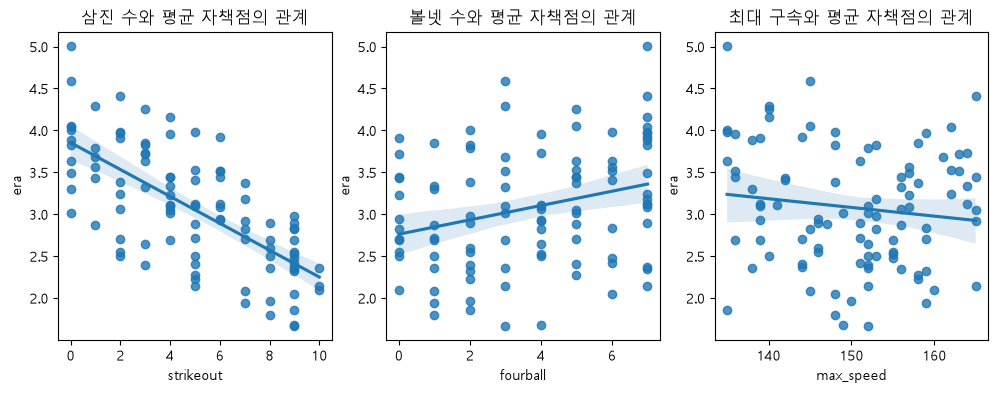

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

# 한글 깨짐 방지
plt.rcParams["font.family"] = "Malgun Gothic"

df = pd.read_csv("./data/베이스볼.csv", encoding="cp949")
# 탐색적 데이터 분석
print(df.describe())

plt.figure(figsize=(12, 4))

# 삼진 수와 평균 자책점의 관계
plt.subplot(1, 3, 1)
sns.regplot(x="strikeout", y="era", data=df)
plt.title("삼진 수와 평균 자책점의 관계")

# 삼진 수와 평균 자책점의 관계
plt.subplot(1, 3, 2)
sns.regplot(x="fourball", y="era", data=df)
plt.title("볼넷 수와 평균 자책점의 관계")


# 삼진 수와 평균 자책점의 관계
plt.subplot(1, 3, 3)
sns.regplot(x="max_speed", y="era", data=df)
plt.title("최대 구속와 평균 자책점의 관계")

plt.show()


# 선형 회귀 모델의 예측 방법

In [15]:
y=df['era']             # 타깃 지정
X=df[['strikeout']]     # 입력 지정

### 임의의 파라미터로 예측하기

In [25]:
w=-0.5; b=5

df['pred_era']=w*X+b
df['error']=df['era']-df['pred_era']

print(df)

    max_speed  fourball  strikeout   era  pred_era  error
0         158         5          7  3.37       1.5   1.87
1         149         5          4  3.01       3.0   0.01
2         153         7          0  3.83       5.0  -1.17
3         136         5          6  3.44       2.0   1.44
4         140         7          4  4.16       3.0   1.16
..        ...       ...        ...   ...       ...    ...
95        144         5          7  2.71       1.5   1.21
96        151         5          3  3.64       3.5   0.14
97        164         4          3  3.73       3.5   0.23
98        148         7          2  3.98       4.0  -0.02
99        146         7          8  2.90       1.0   1.90

[100 rows x 6 columns]


### 예측 결과 시각화 하기

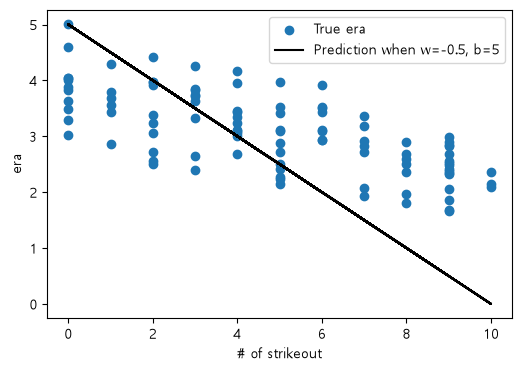

In [19]:
plt.figure(figsize=(6, 4))
plt.scatter(df["strikeout"], df['era'], label="True era")
plt.plot(df['strikeout'], df["pred_era"], "k-", label=f'Prediction when w={w}, b={b}')
plt.xlabel("# of strikeout"); plt.ylabel("era")
plt.legend()
plt.show()

### 예측 오차 평가하기

In [23]:
MSE=np.mean(df['error']**2)
print('평균제곱오차=', np.round(MSE, 3))

평균제곱오차= 1.582


#### MSE 구하는 함수 정의

In [26]:
def mse(true, pred):
    q=np.mean((true-pred)**2)
    return q

# 함수 호출
z=mse(y, df['pred_era'])
print(f'mse 함수로 계산한 평균제곱오차={z: 3f}')

mse 함수로 계산한 평균제곱오차= 1.581994


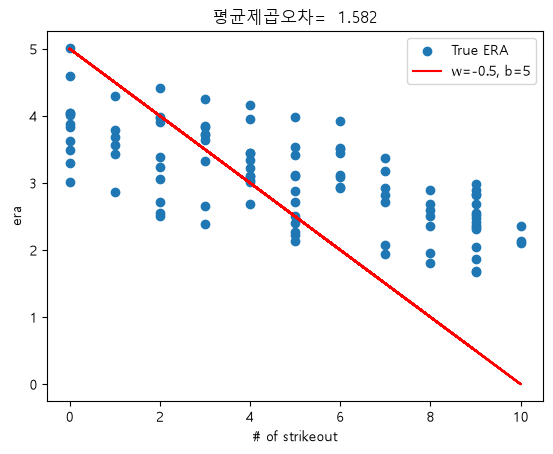

In [ ]:
MSE=np.mean(df['error']**2)

plt.scatter(df["strikeout"], df["era"], label="True ERA")
plt.plot(df["strikeout"], df["pred_era"], "r", label=f'w={w}, b={b}')
plt.xlabel("# of strikeout")
plt.ylabel('era')
plt.legend()
plt.title(f"평균제곱오차= {MSE: .3f}")
plt.show()

### 모델 클래스를 사용해 학습하기

In [ ]:
# 모델 설정
model=LinearRegression()

# 모델 학습
model.fit(X, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[-0.16]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['strikeout']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,3.854
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [45]:
print("가중치(weights)=", model.coef_)
print("편향(bias)=", model.intercept_)

가중치(weights)= [-0.1603438]
편향(bias)= 3.8540639698965196


### 모델 예측과 성능 평가

In [ ]:
y_pred=model.predict(X) # 입력 X를 사용해 타깃의 예측값을 계산
y_pred[:10]

array([2.7316574])

### 손실 계산하기

In [48]:
MSE=mse(y, y_pred)
print(f"평균제곱오차={MSE: .4f}")

평균제곱오차= 0.2548
